In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv('spam.csv',  encoding='latin-1')

In [4]:
df.head()
df.sample(5)
df.shape
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
count,5572,5572,50,12,6
unique,2,5169,43,10,5
top,ham,"Sorry, I'll call later","bt not his girlfrnd... G o o d n i g h t . . .@""","MK17 92H. 450Ppw 16""","GNT:-)"""
freq,4825,30,3,2,2


In [5]:
#  1. Data Cleaning
#  2. FDA
#  3. TEXT Preprocessing
#  4. Model building
#  5. Evalution
#  6. Imrovement 
#  7. Website
#  8. Deploy

## 1. Data Cleaning

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [7]:
# Drop Last 3 cols

df.drop(columns=['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], inplace = True)

In [8]:
df.sample(5)

,v1,v2
1415,ham,Jay is snickering and tells me that x is total...
856,ham,Going to take your babe out ?
69,ham,I plane to give on this month end.
3514,ham,I'm job profile seems like bpo..
4535,ham,Never blame a day in ur life. Good days give u...


In [9]:
# Renaming the cols

df.rename(columns={'v1' : 'target', 'v2': 'text'}, inplace=True)

In [10]:
df.sample(5)

,target,text
155,ham,Aaooooright are you at work?
1407,ham,Then we gotta do it after that
4017,ham,"\GRAN ONLYFOUND OUT AFEW DAYS AGO.CUSOON HONI\"""""
4564,ham,Honeybee Said: *I'm d Sweetest in d World* God...
2616,ham,I went to ur hon lab but no one is there.


In [11]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

In [12]:
df['target'] = encoder.fit_transform(df['target'])

In [13]:
# missing values

df.isnull().sum()

target    0
text      0
dtype: int64

In [14]:
# Check for Dublicate value

df.duplicated().sum()

np.int64(403)

In [15]:
# remove Duplicated Values

df = df.drop_duplicates(keep='first')

In [16]:
df.shape

(5169, 2)

# 2. EDA

In [17]:
df['target'].value_counts()

target
0    4516
1     653
Name: count, dtype: int64

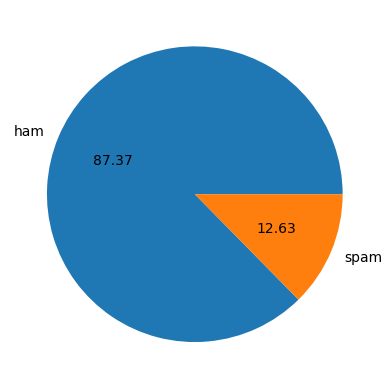

In [18]:
import matplotlib.pyplot as plt

plt.pie(
    df['target'].value_counts(),
    labels = ['ham','spam'],
    autopct="%0.2f"
)

plt.show()
    

In [19]:
# Data is Imbalaced

In [20]:
import nltk
nltk.download('punkt')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\nites\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [21]:
df["num_characters"] = df["text"].apply(len)

In [22]:
df

,target,text,num_characters
0,0,"Go until jurong point, crazy.. Available only ...",111
1,0,Ok lar... Joking wif u oni...,29
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,0,U dun say so early hor... U c already then say...,49
4,0,"Nah I don't think he goes to usf, he lives aro...",61
...,...,...,...
5567,1,This is the 2nd time we have tried 2 contact u...,161
5568,0,Will Ì_ b going to esplanade fr home?,37
5569,0,"Pity, * was in mood for that. So...any other s...",57
5570,0,The guy did some bitching but I acted like i'd...,125


In [23]:
# num of words

df["num_words"] = df['text'].apply(lambda x:len(nltk.word_tokenize(x)))

In [24]:
df.head()

,target,text,num_characters,num_words
0,0,"Go until jurong point, crazy.. Available only ...",111,24
1,0,Ok lar... Joking wif u oni...,29,8
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37
3,0,U dun say so early hor... U c already then say...,49,13
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15


In [25]:
df["num_sentences"] = df['text'].apply(lambda x:len(nltk.sent_tokenize(x)))

In [26]:
df.head()

,target,text,num_characters,num_words,num_sentences
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2
1,0,Ok lar... Joking wif u oni...,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,0,U dun say so early hor... U c already then say...,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1


In [27]:
df[['num_characters', 'num_words', 'num_sentences']].describe()

,num_characters,num_words,num_sentences
count,5169.000000,5169.000000,5169.000000
mean,78.977945,18.455794,1.965564
std,58.236293,13.324758,1.448541
min,2.000000,1.000000,1.000000
25%,36.000000,9.000000,1.000000
50%,60.000000,15.000000,1.000000
75%,117.000000,26.000000,2.000000
max,910.000000,220.000000,38.000000


In [28]:
# HAM Messages

df[df["target"] == 0][['num_characters', 'num_words', 'num_sentences']].describe()

,num_characters,num_words,num_sentences
count,4516.000000,4516.000000,4516.000000
mean,70.459256,17.123782,1.820195
std,56.358207,13.493970,1.383657
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,52.000000,13.000000,1.000000
75%,90.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


In [29]:
# Spam Meassages

df[df["target"] == 1][['num_characters', 'num_words', 'num_sentences']].describe()

,num_characters,num_words,num_sentences
count,653.000000,653.000000,653.000000
mean,137.891271,27.667688,2.970904
std,30.137753,7.008418,1.488425
min,13.000000,2.000000,1.000000
25%,132.000000,25.000000,2.000000
50%,149.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,224.000000,46.000000,9.000000


<Axes: xlabel='num_characters', ylabel='Count'>

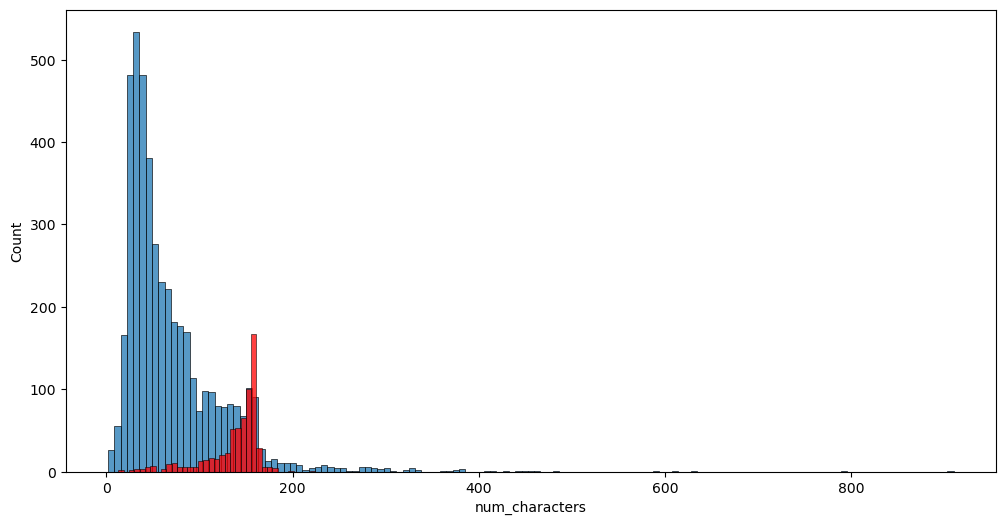

In [30]:
import seaborn as sns

plt.figure(figsize=(12,6))
sns.histplot(df[df["target"] == 0]['num_characters'])
sns.histplot(df[df["target"] == 1]['num_characters'], color = "red")

    

<Axes: xlabel='num_words', ylabel='Count'>

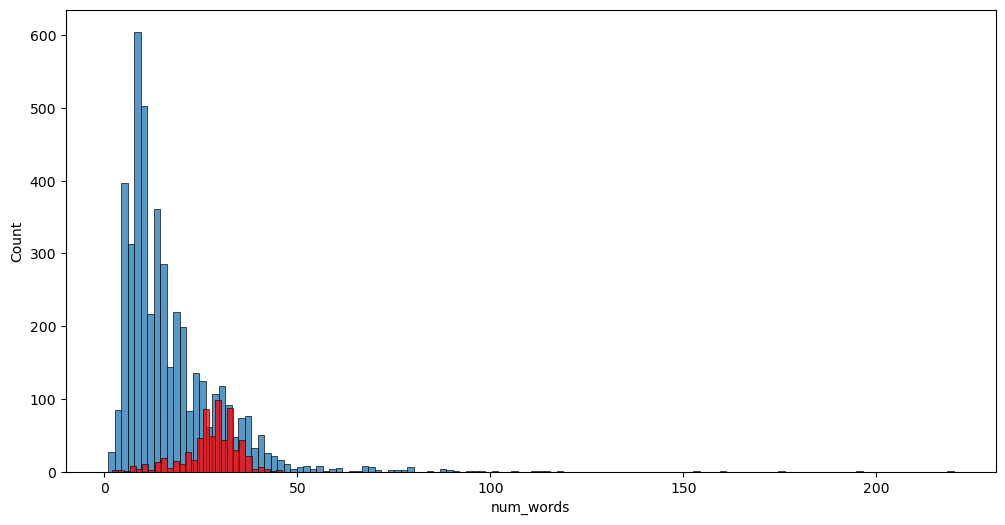

In [31]:
plt.figure(figsize=(12,6))
sns.histplot(df[df["target"] == 0]['num_words'])
sns.histplot(df[df["target"] == 1]['num_words'], color = "red")

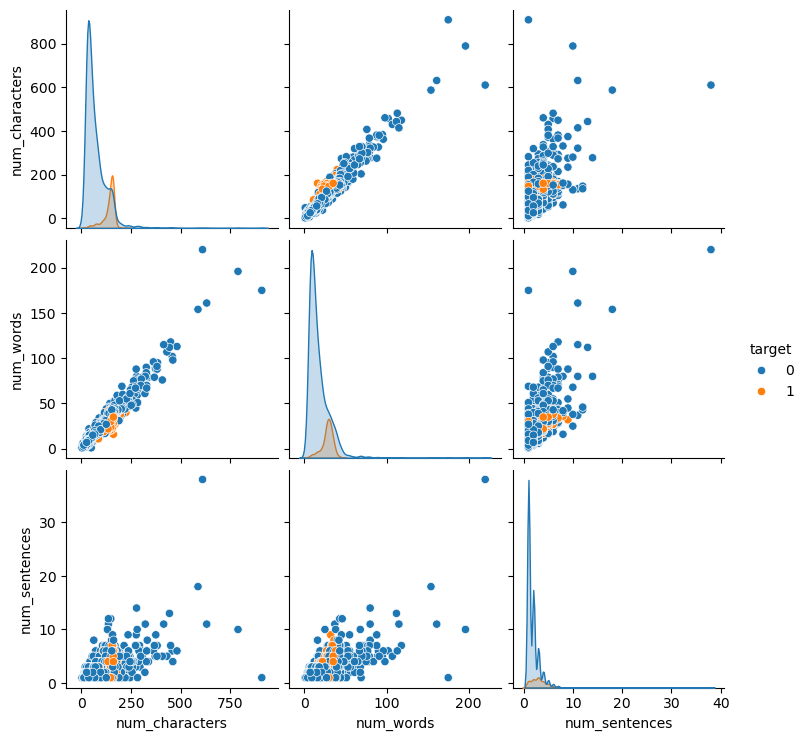

In [32]:
sns.pairplot(
    df,
    hue='target'
)

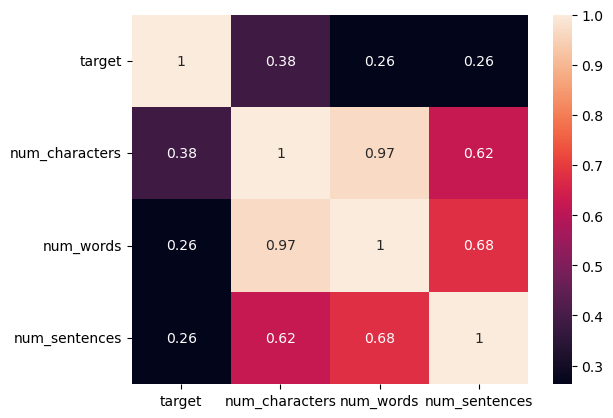

In [33]:
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

## 3. Data Preprocessing
###  -> Lower Case
###  -> Tokenization
###  -> Removing special characters
###  -> Removing stopwords and punctuation
###  -> Stemming

In [34]:
nltk.download("punkt_tab")
nltk.download("stopwords")

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\nites\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\nites\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [35]:
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

In [36]:
from nltk.stem import PorterStemmer

In [37]:
import string
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

# Initialize the stemmer outside the function for better performance
ps = PorterStemmer()


def transform_text(text):
    # 1. Lowercase the text
    text = text.lower()

    # 2. Tokenize into words
    words = nltk.word_tokenize(text)

    # 3. Remove non-alphanumeric characters
    alphanumeric_words = []
    for i in words:
        if i.isalnum():
            alphanumeric_words.append(i)

    # 4. Remove stopwords and punctuation
    filtered_words = []
    stop_words = set(stopwords.words("english"))
    for i in alphanumeric_words:
        if i not in stop_words and i not in string.punctuation:
            filtered_words.append(i)

    # 5. Apply stemming
    stemmed_words = []
    for i in filtered_words:
        stemmed_words.append(ps.stem(i))

    # 6. Join back into a single string
    return " ".join(stemmed_words)


In [38]:
df["transformed_text"] = df["text"].apply(transform_text)

In [39]:
df

,target,text,num_characters,num_words,num_sentences,transformed_text
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think goe usf live around though
...,...,...,...,...,...,...
5567,1,This is the 2nd time we have tried 2 contact u...,161,35,4,2nd time tri 2 contact u pound prize 2 claim e...
5568,0,Will Ì_ b going to esplanade fr home?,37,9,1,b go esplanad fr home
5569,0,"Pity, * was in mood for that. So...any other s...",57,15,2,piti mood suggest
5570,0,The guy did some bitching but I acted like i'd...,125,27,1,guy bitch act like interest buy someth els nex...


In [40]:
from wordcloud import WordCloud
wc = WordCloud(width = 500, height = 500, min_font_size= 10, background_color = 'white')

In [41]:
pip install wordcloud

Note: you may need to restart the kernel to use updated packages.


In [42]:
spam_wc = wc.generate(df[df["target"] == 1]["transformed_text"].str.cat(sep=" "))

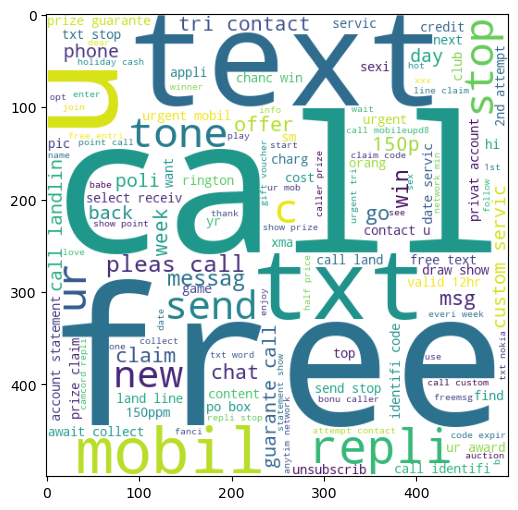

In [43]:
plt.figure(figsize=(15, 6))
plt.imshow(spam_wc)

In [44]:
ham_wc = wc.generate(df[df["target"] == 0]["transformed_text"].str.cat(sep=" "))

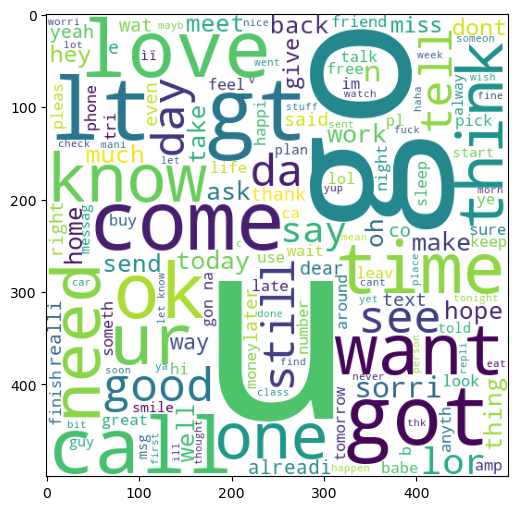

In [45]:
plt.figure(figsize=(15, 6))
plt.imshow(ham_wc)

In [46]:
df.head()

,target,text,num_characters,num_words,num_sentences,transformed_text
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think goe usf live around though


In [47]:
spam_corpus = []
for msg in df[df["target"] == 1]["transformed_text"].tolist():
    for word in msg.split():
        spam_corpus.append(word)

In [48]:
len(spam_corpus)

9939

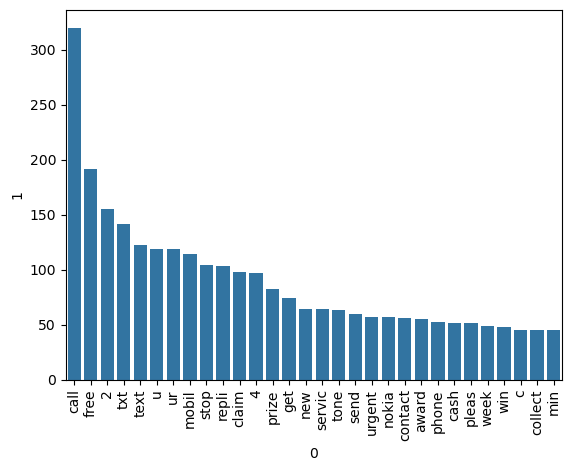

In [50]:
from collections import Counter
df_most_common = pd.DataFrame(Counter(spam_corpus).most_common(30))
sns.barplot(x = df_most_common[0], y = df_most_common[1])
plt.xticks(rotation="vertical")
plt.show()

In [53]:
ham_corpus = []
for msg in df[df["target"] == 0]["transformed_text"].tolist():
    for word in msg.split():
        ham_corpus.append(word)

In [54]:
len(ham_corpus)

35404

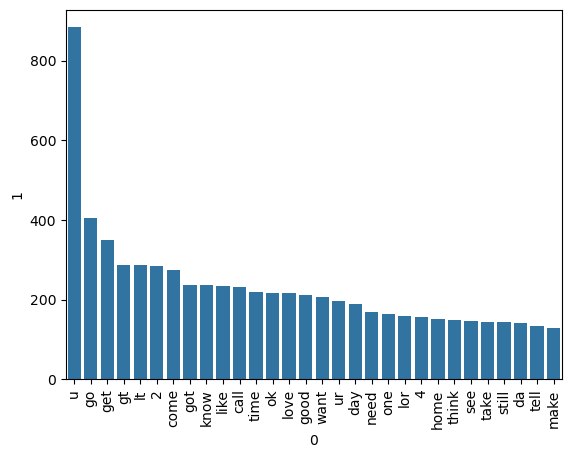

In [58]:
df_most_common_1 = pd.DataFrame(Counter(ham_corpus).most_common(30))
sns.barplot( x = df_most_common_1[0], y = df_most_common_1[1])
plt.xticks(rotation = "vertical")
plt.show()

## 4. Model Building

In [84]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
cv = CountVectorizer()
tfidf = TfidfVectorizer()

In [85]:
X = tfidf.fit_transform(df['transformed_text']).toarray()

In [86]:
X.shape


(5169, 6708)

In [87]:
y = df['target'].values

In [88]:
y

array([0, 0, 1, ..., 0, 0, 0])

In [89]:
from sklearn.model_selection import train_test_split


In [90]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2   , random_state = 2
)

In [91]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score

In [92]:
gnb = GaussianNB()
mnb = MultinomialNB()
bnb = BernoulliNB()

In [93]:
gnb.fit(X_train, y_train)
y_pred1 = gnb.predict(X_test)
print(accuracy_score(y_test, y_pred1))
print(confusion_matrix(y_test, y_pred1))
print(precision_score(y_test, y_pred1))

0.8762088974854932
[[793 103]
 [ 25 113]]
0.5231481481481481


In [94]:
mnb.fit(X_train, y_train)
y_pred2 = mnb.predict(X_test)
print(accuracy_score(y_test, y_pred2))
print(confusion_matrix(y_test, y_pred2))
print(precision_score(y_test, y_pred2))

0.9593810444874274
[[896   0]
 [ 42  96]]
1.0


In [95]:
bnb.fit(X_train, y_train)
y_pred3 = bnb.predict(X_test)
print(accuracy_score(y_test, y_pred3))
print(confusion_matrix(y_test, y_pred3))
print(precision_score(y_test, y_pred3))

0.9700193423597679
[[893   3]
 [ 28 110]]
0.9734513274336283


In [ ]:
# I Choose tfidf ---> MNB

In [98]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import ExtraTreesClassifier  
from sklearn.ensemble import GradientBoostingClassifier  
from xgboost import XGBClassifier

In [72]:
svc = SVC(kernel = 'sigmoid', gamma = 1.0)
knc = KNeighborsClassifier()
mnb = MultinomialNB()
dtc = DecisionTreeClassifier(max_depth = 5)
lrc = LogisticRegression(penalty="l1", solver="liblinear")
rfc = RandomForestClassifier(n_estimators = 50, random_state=2)
abc = AdaBoostClassifier(n_estimators=50, random_state=2)
bc = BaggingClassifier(n_estimators=50, random_state=2)
etc = ExtraTreesClassifier(n_estimators=50, random_state=2)
gbdt = GradientBoostingClassifier(n_estimators=50, random_state=2)
xgb = XGBClassifier(n_estimators=50, random_state=2)

In [73]:
clfs = {
    'SVC' : svc,
    'KN' : knc,
    'NB' : mnb,
    'DT' : dtc,
    'LR' : lrc,
    'RF' : rfc,
    'AdaBoost' : abc,
    'Bgc' : etc,
    'ETC' : etc,
    'GBDT' : gbdt,
    'xgb' : xgb
}

In [74]:
def train_classifier(clf, X_train, y_train, X_test, y_test):
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)

    return accuracy,precision

In [75]:
train_classifier(svc,X_train, y_train, X_test, y_test)

(0.9729206963249516, 0.9741379310344828)

In [76]:
accuracy = []
precision = []

for name,clf in clfs.items():
    current_accuracy, current_precision = train_classifier(clf, X_train, y_train, X_test, y_test)

    print("For", name)
    print("Accuracy : ", current_accuracy)
    print("precision : ", current_precision)

    accuracy.append(current_accuracy)
    precision.append(current_precision)


For SVC
Accuracy :  0.9729206963249516
precision :  0.9741379310344828
For KN
Accuracy :  0.9003868471953579
precision :  1.0
For NB
Accuracy :  0.9593810444874274
precision :  1.0
For DT
Accuracy :  0.9352030947775629
precision :  0.8380952380952381
For LR
Accuracy :  0.9516441005802708
precision :  0.94
For RF
Accuracy :  0.971953578336557
precision :  1.0
For AdaBoost
Accuracy :  0.9245647969052224
precision :  0.8409090909090909
For Bgc
Accuracy :  0.9729206963249516
precision :  0.9824561403508771
For ETC
Accuracy :  0.9729206963249516
precision :  0.9824561403508771
For GBDT
Accuracy :  0.9526112185686654
precision :  0.9238095238095239
For xgb
Accuracy :  0.9709864603481625
precision :  0.9426229508196722


In [80]:
#  CORRECT: Pass the completed numeric lists here
performance_df = pd.DataFrame(
    {"Algorithm": clfs.keys(), "Accuracy": accuracy, "Precision": precision}
).sort_values("Precision", ascending=False)

print(performance_df)


   Algorithm  Accuracy  Precision
1         KN  0.900387   1.000000
2         NB  0.959381   1.000000
5         RF  0.971954   1.000000
8        ETC  0.972921   0.982456
7        Bgc  0.972921   0.982456
0        SVC  0.972921   0.974138
10       xgb  0.970986   0.942623
4         LR  0.951644   0.940000
9       GBDT  0.952611   0.923810
6   AdaBoost  0.924565   0.840909
3         DT  0.935203   0.838095


In [81]:
performance_df1 = pd.melt(performance_df, id_vars = "Algorithm")

In [82]:
performance_df1

,Algorithm,variable,value
0,KN,Accuracy,0.900387
1,NB,Accuracy,0.959381
2,RF,Accuracy,0.971954
3,ETC,Accuracy,0.972921
4,Bgc,Accuracy,0.972921
5,SVC,Accuracy,0.972921
6,xgb,Accuracy,0.970986
7,LR,Accuracy,0.951644
8,GBDT,Accuracy,0.952611
9,AdaBoost,Accuracy,0.924565


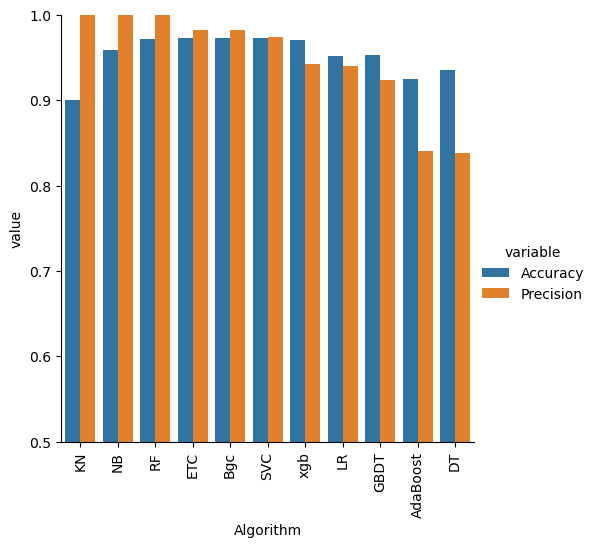

In [85]:
sns.catplot(x = 'Algorithm', y = 'value',
            hue = 'variable', data =  performance_df1, kind = 'bar' , height = 5)

plt.ylim(0.5, 1.0)
plt.xticks(rotation = 'vertical')
plt.show()

In [86]:
import pickle
pickle.dump(tfidf,open('vectorizer.pkl', 'wb'))
pickle.dump(mnb,open('model.pkl', 'wb'))